Quantum Circuit:
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Measurement Counts:
{'1': 500, '0': 524}


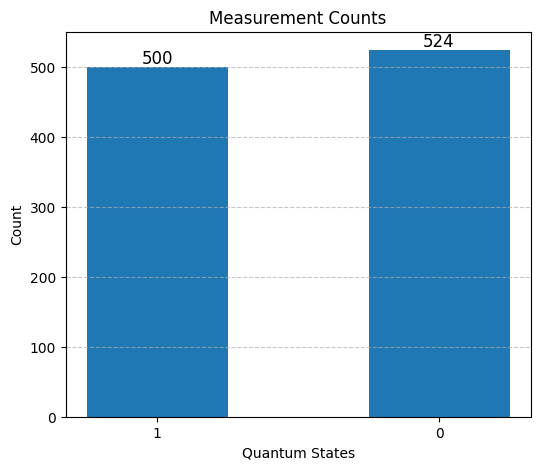

In [16]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

qc = QuantumCircuit(1, 1)

qc.h(0)

qc.measure(0, 0)

print("Quantum Circuit:")
print(qc)

simulator = AerSimulator()
job = simulator.run(qc, shots=1024)
result = job.result()

counts = result.get_counts()

print("\nMeasurement Counts:")
print(counts)

plot_histogram(counts, title="Quantum Measurement Histogram")
plt.show()

states = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(6,5))
bars = plt.bar(states, values, width=0.5)

plt.title("Measurement Counts")
plt.xlabel("Quantum States")
plt.ylabel("Count")
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 5,
        str(int(height)),
        ha='center',
        fontsize=12
    )

plt.show()

Quantum Circuit:

     ┌───┐┌─┐      
q_0: ┤ H ├┤M├──────
     ├───┤└╥┘┌─┐   
q_1: ┤ H ├─╫─┤M├───
     ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├─╫──╫─┤M├
     └───┘ ║  ║ └╥┘
c: 3/══════╩══╩══╩═
           0  1  2 

Measurement Counts:

{'001': 976, '011': 998, '000': 964, '111': 1003, '100': 1043, '010': 1087, '101': 964, '110': 965}


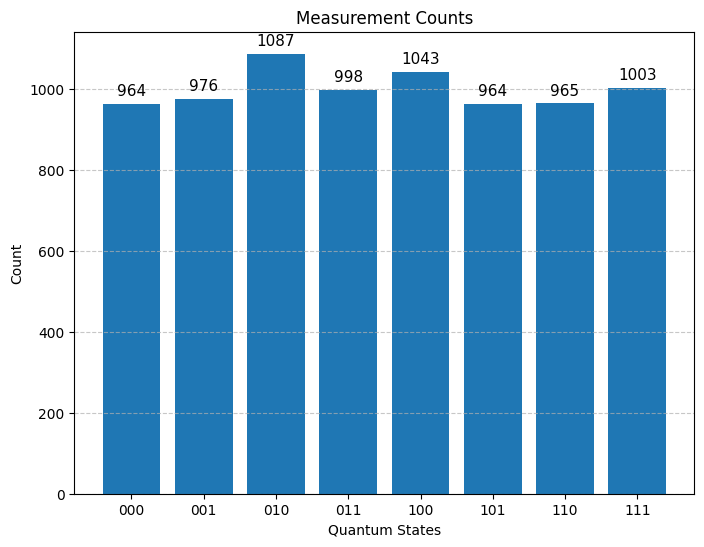


Observed Probabilities:

000 : 0.120
001 : 0.122
010 : 0.136
011 : 0.125
100 : 0.130
101 : 0.120
110 : 0.121
111 : 0.125

Theoretical Probability for each state = 1/8 = 0.125


In [15]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import mplcursors

qc = QuantumCircuit(3, 3)

qc.h(0)
qc.h(1)
qc.h(2)

qc.measure([0, 1, 2], [0, 1, 2])

print("Quantum Circuit:\n")
print(qc)

qc.draw("mpl")
plt.show()

simulator = AerSimulator()

job = simulator.run(qc, shots=8000)

result = job.result()

counts = result.get_counts()

print("\nMeasurement Counts:\n")
print(counts)

plot_histogram(counts, title="Quantum Measurement Histogram")
plt.show()

states = sorted(counts.keys())
values = [counts[state] for state in states]

fig, ax = plt.subplots(figsize=(8,6))

bars = ax.bar(states, values)

ax.set_title("Measurement Counts")
ax.set_xlabel("Quantum States")
ax.set_ylabel("Count")

ax.grid(axis="y", linestyle="--", alpha=0.7)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        str(int(height)),
        ha="center",
        fontsize=11
    )

plt.show()

print("\nObserved Probabilities:\n")

shots = 8000

for state in states:
    probability = counts[state] / shots
    print(f"{state} : {probability:.3f}")

print("\nTheoretical Probability for each state = 1/8 = 0.125")